# 1. Entendimento do Problema / Contexto de Negócio

**Problema a ser resolvido:** a empresa enfrenta dificuldade na fidelização dos clientes, com um número elevado de cancelamentos.

**Solução:** desenvolver um modelo preditivo para identificar os clientes mais propensos a cancelar, permitindo a criação de campanhas e estratégias de fidelização.

**Quem vai utilizar a solução:** times de dados, marketing e gestão.

**Resultado mais prejudicial:** falso negativo (deixar de identificar um cliente que realmente irá cancelar).

# 2. Coleta e Carregamento dos Dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import shap

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, ConfusionMatrixDisplay,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option('display.max_columns', None)
optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 42
df = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 3. EDA (Análise Exploratória dos Dados)

In [2]:
print(df.shape)
print()
print(df.dtypes)

(7043, 21)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [3]:
df.describe(include= 'all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Auditoria de Qualidade dos Dados

In [8]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Quem são os 11 nulos de TotalCharges?
print(df.loc[df['TotalCharges'].isna(), 'tenure'].value_counts())

tenure
0    11
Name: count, dtype: int64


Não foram encontrados registros duplicados. Foram identificados 11 valores ausentes em `TotalCharges`, **todos de clientes com `tenure = 0`** (ainda sem nenhuma cobrança acumulada). O tratamento está na etapa de pré-processamento.

Verificando o balanceamento da variável alvo (Churn).

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


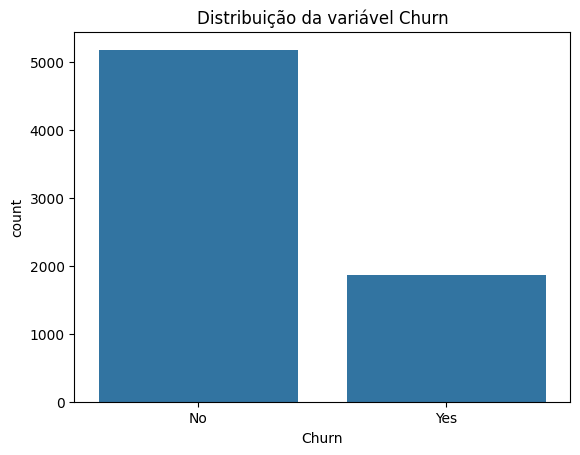

In [11]:
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize= True)*100).round(2))

sns.countplot(data= df , x='Churn')
plt.title("Distribuição da variável Churn")
plt.show()

### Análise Univariada

In [12]:
numericas = [c for c in df.select_dtypes(include = ['int64', 'float64']).columns if c not in ['SeniorCitizen']]
print(numericas)

['tenure', 'MonthlyCharges', 'TotalCharges']


In [13]:
df[numericas].skew()

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.961642
dtype: float64

In [14]:
df[numericas].kurt()

tenure           -1.387372
MonthlyCharges   -1.257260
TotalCharges     -0.231799
dtype: float64

In [15]:
categoricas = [c for c in df.select_dtypes(exclude = 'number').columns if c not in ('Churn', 'customerID')]

print(categoricas)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [16]:
for c in categoricas :
    print(df[c].value_counts())
    print()

gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

StreamingTV
No                 

### Verificação de Outliers (Método IQR)

In [17]:
outliers_resumo = {}
for col in numericas :
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers =df [(df[col] < limite_inferior) | (df[col] > limite_superior)]
    outliers_resumo[col] = outliers.shape[0]

pd.Series(outliers_resumo , name = 'qtd_outliers')

tenure            0
MonthlyCharges    0
TotalCharges      0
Name: qtd_outliers, dtype: int64

### Análise Bivariada


tenure
Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


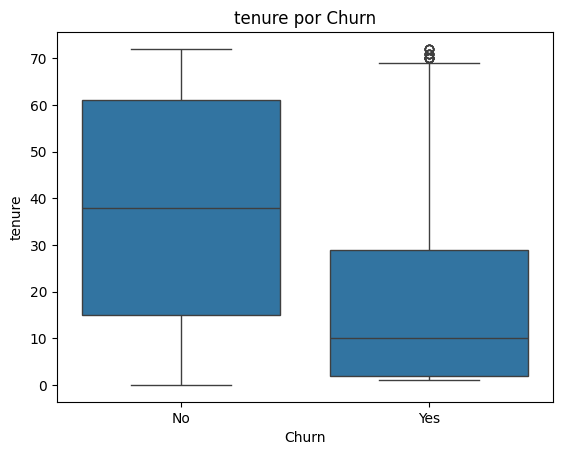


MonthlyCharges
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


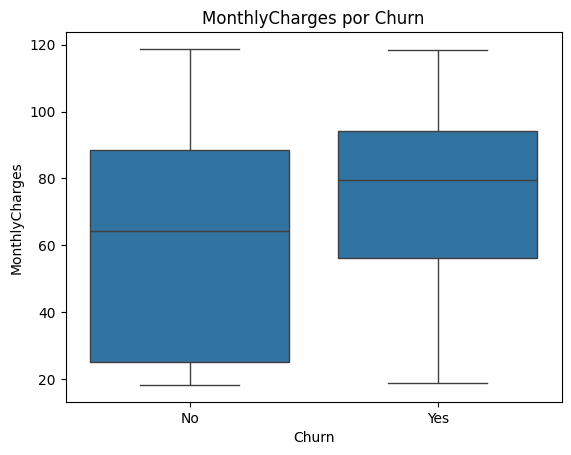


TotalCharges
Churn
No     1683.60
Yes     703.55
Name: TotalCharges, dtype: float64


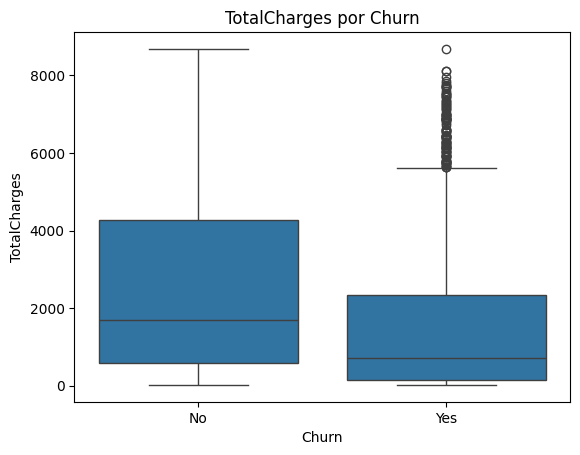

In [18]:
for col in numericas:
    print(f'\n{col}')
    print(df.groupby('Churn')[col].median())

    sns.boxplot(data = df , x= 'Churn' , y = col)
    plt.title(f'{col} por Churn')
    plt.show()


gender
Churn         No       Yes
gender                    
Female  0.730791  0.269209
Male    0.738397  0.261603


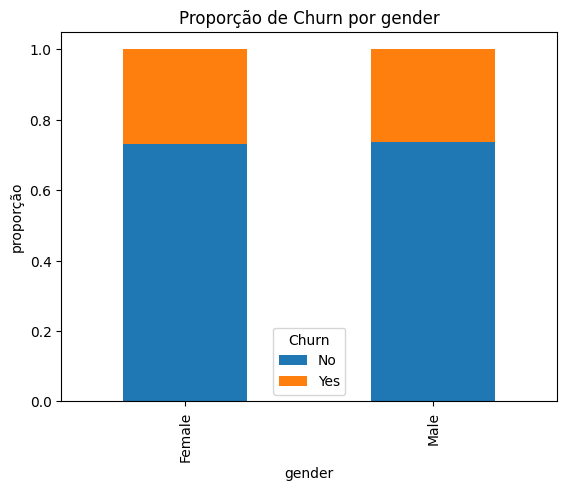


Partner
Churn          No       Yes
Partner                    
No       0.670420  0.329580
Yes      0.803351  0.196649


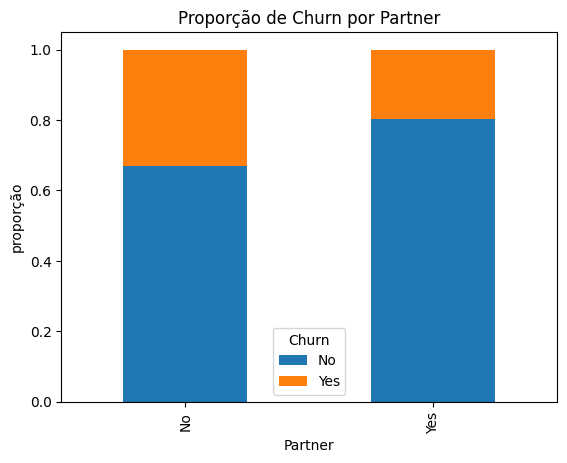


Dependents
Churn             No       Yes
Dependents                    
No          0.687209  0.312791
Yes         0.845498  0.154502


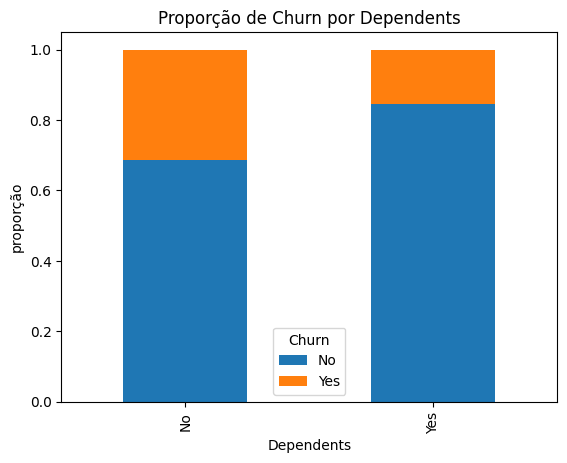


PhoneService
Churn               No       Yes
PhoneService                    
No            0.750733  0.249267
Yes           0.732904  0.267096


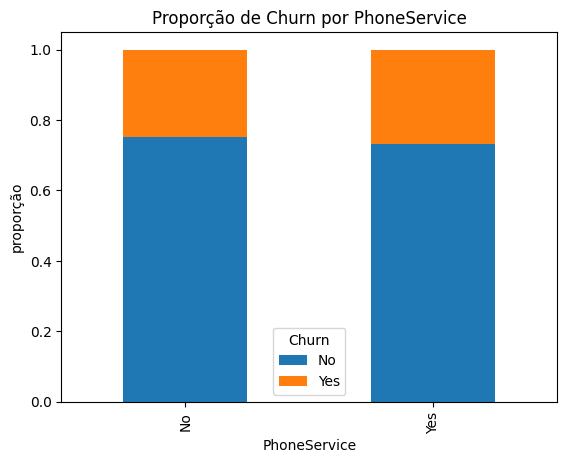


MultipleLines
Churn                   No       Yes
MultipleLines                       
No                0.749558  0.250442
No phone service  0.750733  0.249267
Yes               0.713901  0.286099


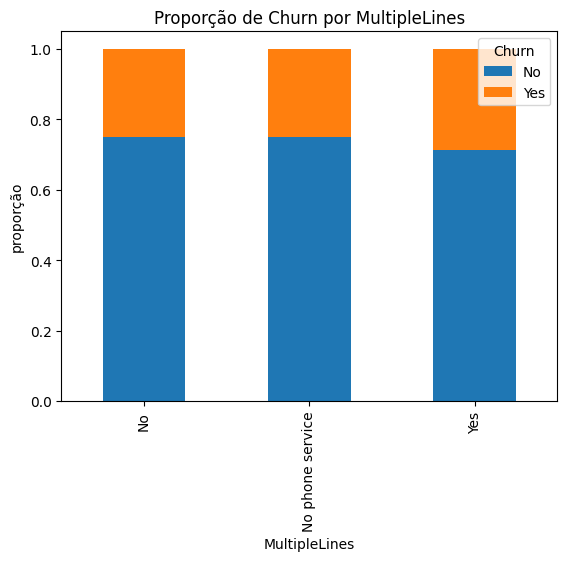


InternetService
Churn                  No       Yes
InternetService                    
DSL              0.810409  0.189591
Fiber optic      0.581072  0.418928
No               0.925950  0.074050


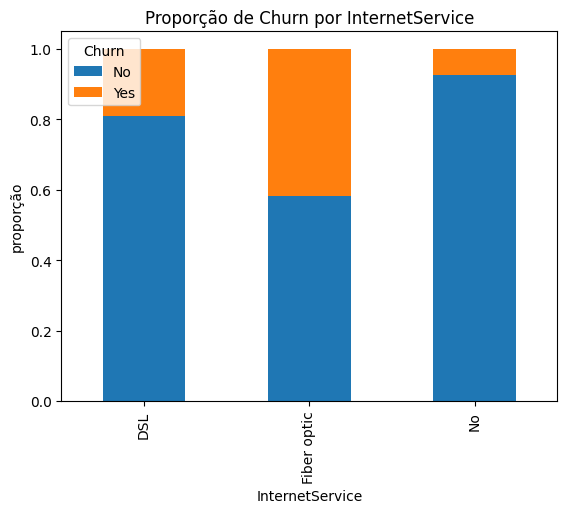


OnlineSecurity
Churn                      No       Yes
OnlineSecurity                         
No                   0.582333  0.417667
No internet service  0.925950  0.074050
Yes                  0.853888  0.146112


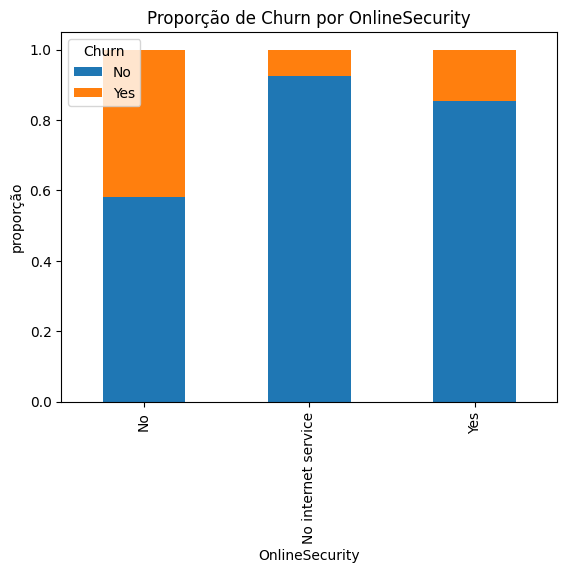


OnlineBackup
Churn                      No       Yes
OnlineBackup                           
No                   0.600712  0.399288
No internet service  0.925950  0.074050
Yes                  0.784685  0.215315


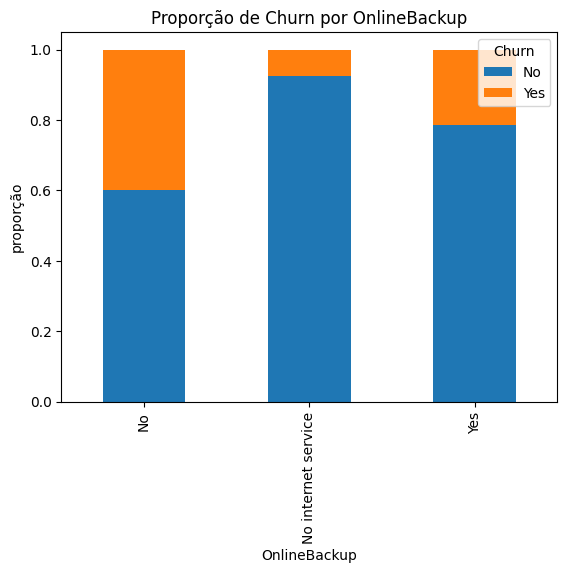


DeviceProtection
Churn                      No       Yes
DeviceProtection                       
No                   0.608724  0.391276
No internet service  0.925950  0.074050
Yes                  0.774979  0.225021


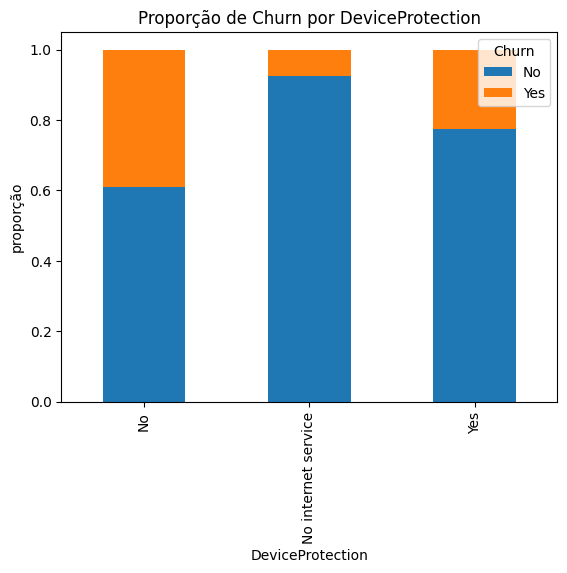


TechSupport
Churn                      No       Yes
TechSupport                            
No                   0.583645  0.416355
No internet service  0.925950  0.074050
Yes                  0.848337  0.151663


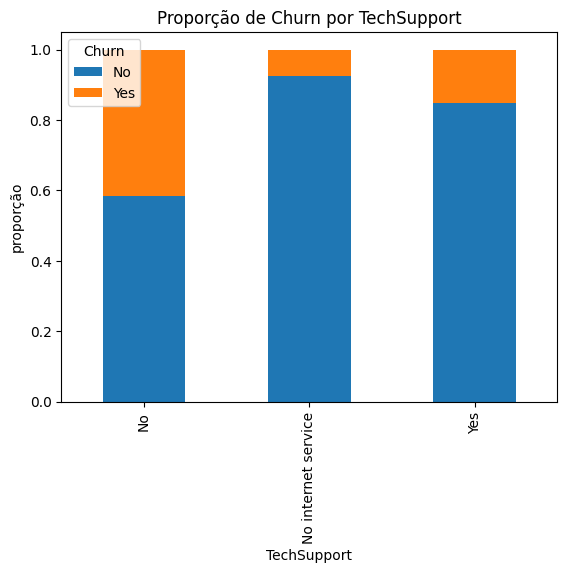


StreamingTV
Churn                      No       Yes
StreamingTV                            
No                   0.664769  0.335231
No internet service  0.925950  0.074050
Yes                  0.699298  0.300702


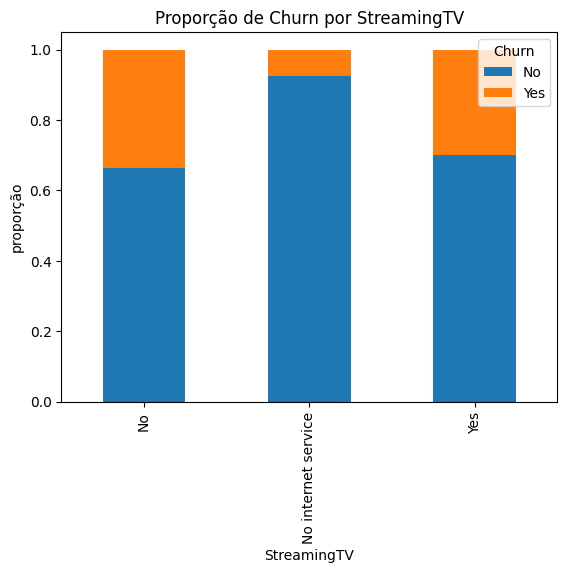


StreamingMovies
Churn                      No       Yes
StreamingMovies                        
No                   0.663196  0.336804
No internet service  0.925950  0.074050
Yes                  0.700586  0.299414


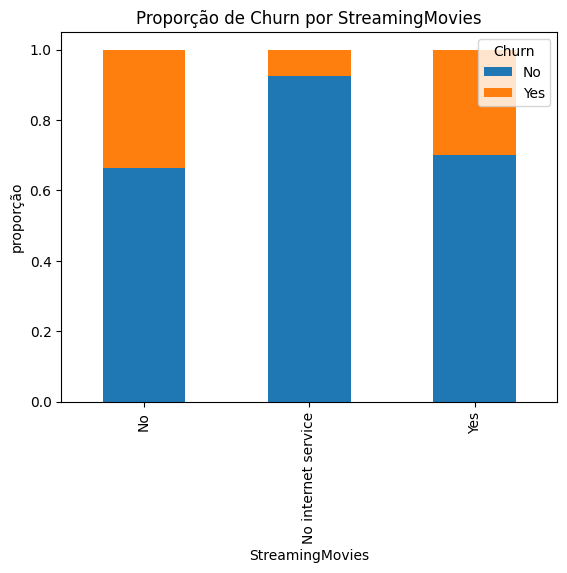


Contract
Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319


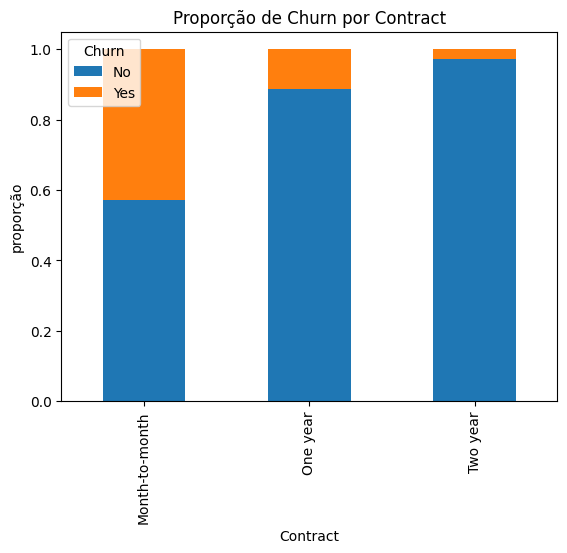


PaperlessBilling
Churn                   No       Yes
PaperlessBilling                    
No                0.836699  0.163301
Yes               0.664349  0.335651


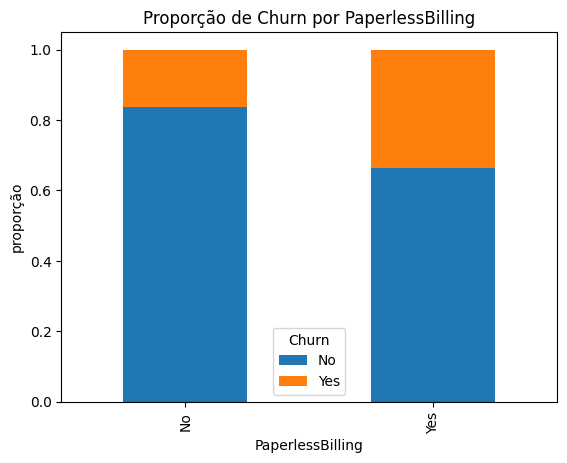


PaymentMethod
Churn                            No       Yes
PaymentMethod                                
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
Electronic check           0.547146  0.452854
Mailed check               0.808933  0.191067


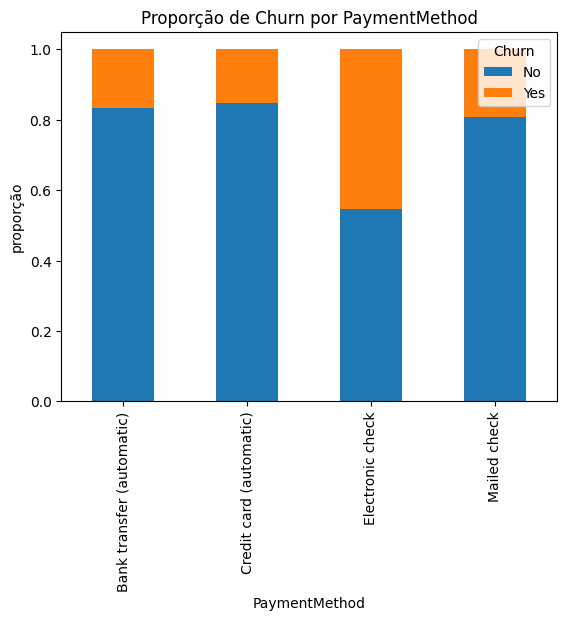

In [19]:
for col in categoricas:
    tab = pd.crosstab(df[col], df['Churn'], normalize = 'index')
    print(f'\n{col}')
    print(tab)

    tab.plot(kind = 'bar', stacked = True)
    plt.title(f'Proporção de Churn por {col}')
    plt.ylabel('proporção')
    plt.show()

### Insights da EDA

* A base possui 7043 clientes e 21 colunas, sem registros duplicados.
* A variável alvo está desbalanceada: 73,46% dos clientes não cancelam (No) e 26,54% cancelam (Yes).
* A coluna TotalCharges apresentou 11 valores ausentes após a conversão para numérico, todos referentes a clientes com tenure igual a 0 (clientes muito novos).
* Não foram identificados outliers relevantes nas variáveis numéricas pelo método do IQR.
* TotalCharges apresenta assimetria positiva (skew próximo de 0,96), indicando concentração de clientes com valores acumulados baixos.
* Clientes que cancelam têm tempo de permanência (tenure) mediano bem menor (10 meses contra 38 meses dos que permanecem), mensalidade (MonthlyCharges) mais alta (79,65 contra 64,43) e gasto total (TotalCharges) menor. Ou seja, cancelam cedo, pagando mais por mês.
* O tipo de contrato é um forte diferenciador: contratos mensais (Month to month) têm taxa de churn de 42,7%, contra 11,3% nos contratos de 1 ano e 2,8% nos de 2 anos.
* Clientes com internet via fibra ótica (Fiber optic) cancelam mais (41,9%) do que os de DSL (18,9%) e os sem internet (7,4%).
* A ausência de serviços adicionais como OnlineSecurity, TechSupport, OnlineBackup e DeviceProtection está associada a taxas de churn mais altas.
* O método de pagamento Electronic check concentra a maior taxa de churn (45,3%), bem acima dos demais métodos (entre 15% e 19%).
* Clientes com PaperlessBilling ativo cancelam mais (33,6%) do que os que não usam (16,3%).
* Gênero e PhoneService têm pouca relação com o churn, pouco úteis como preditores isolados.

# 4. Pré-Processamento

## 4.1 Limpeza (regras determinísticas)

Estas duas correções são **regras de negócio**, não algo aprendido dos dados. Por isso podem ser feitas antes do split sem causar vazamento.

* `TotalCharges` nulo só ocorre com `tenure = 0` (nenhum mês cobrado ainda). O valor correto é **0**, não a mediana.
* `No phone service` e `No internet service` apenas repetem `PhoneService` e `InternetService`. Recodificados para `No`, evitam dummies redundantes.

In [20]:
df_bruto = df.copy()   # cópia só para o diagnóstico de colinearidade abaixo

assert df.loc[df['TotalCharges'].isna(), 'tenure'].eq(0).all()
df['TotalCharges'] = df['TotalCharges'].fillna(0)

servicos_internet = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')
df[servicos_internet] = df[servicos_internet].replace('No internet service', 'No')

print('Nulos restantes:', int(df.isna().sum().sum()))

Nulos restantes: 0


### Diagnóstico: o efeito da recodificação na colinearidade

VIF (fator de inflação da variância) das variáveis dummy. Valores acima de 10 indicam colinearidade forte, e `inf` indica redundância perfeita.

In [21]:
def vif(X):
    X = X.astype(float)
    saida = {}
    for c in X.columns:
        outras = X.drop(columns=c)
        r2 = LinearRegression().fit(outras, X[c]).score(outras, X[c])
        saida[c] = np.inf if r2 > 0.999999 else 1 / (1 - r2)
    return pd.Series(saida).sort_values(ascending=False)

def dummies_para_vif(base):
    X = base.drop(columns=['customerID', 'Churn']).copy()
    X['TotalCharges'] = X['TotalCharges'].fillna(0)
    return pd.get_dummies(X, drop_first=True)

vif_antes = vif(dummies_para_vif(df_bruto))
vif_depois = vif(dummies_para_vif(df))

pd.concat([vif_antes.head(8).round(1).rename('VIF').reset_index().rename(columns={'index': 'Antes: variável'}),
           vif_depois.head(8).round(1).rename('VIF').reset_index().rename(columns={'index': 'Depois: variável'})], axis=1)

,Antes: variável,VIF,Depois: variável,VIF
0,MultipleLines_No phone service,inf,MonthlyCharges,865.1
1,PhoneService_Yes,inf,InternetService_Fiber optic,148.3
2,InternetService_No,inf,InternetService_No,104.2
3,OnlineSecurity_No internet service,inf,PhoneService_Yes,34.9
4,DeviceProtection_No internet service,inf,StreamingMovies_Yes,24.1
5,OnlineBackup_No internet service,inf,StreamingTV_Yes,24.1
6,TechSupport_No internet service,inf,TotalCharges,10.8
7,StreamingTV_No internet service,inf,tenure,7.5


Antes, as dummies de "sem serviço" eram combinações exatas de outras colunas (VIF infinito). Depois da recodificação esse problema some. O que sobra de VIF alto é natural: `MonthlyCharges` é, em boa parte, a soma dos serviços contratados, e `TotalCharges` é aproximadamente `tenure × MonthlyCharges`. Isso importa para a leitura dos coeficientes da Regressão Logística.

## 4.2 Divisão entre Treino e Teste

Separação entre as variáveis explicativas (X) e a variável alvo (y), com split estratificado. O teste só é usado na avaliação final.

In [22]:
x = df.drop(columns= ['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=SEED)

print('Formato do X, em treino:', x_train.shape, 'teste:', x_test.shape)
print()
print('Proporção do Churn no treino:')
print((y_train.value_counts(normalize = True) * 100).round(2))
print('Proporção do Churn no teste:')
print((y_test.value_counts(normalize = True) * 100).round(2))

Formato do X, em treino: (5634, 19) teste: (1409, 19)

Proporção do Churn no treino:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64
Proporção do Churn no teste:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


## 4.3 Pipeline de pré-processamento

Em vez de `get_dummies` separado em treino e teste com `reindex`, o encoding e a padronização ficam dentro de um `ColumnTransformer` que entra no `Pipeline` de cada modelo. Assim, tudo é ajustado só no treino (inclusive dentro de cada fold da validação cruzada), e categorias novas no teste não quebram o código.

* Numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`): `StandardScaler`.
* Categóricas: `OneHotEncoder` removendo a primeira categoria (evita a armadilha da variável dummy).
* `SeniorCitizen` já é 0/1 e passa direto.

In [23]:
colunas_num = ['tenure', 'MonthlyCharges', 'TotalCharges']
colunas_cat = x.select_dtypes(exclude='number').columns.tolist()

def novo_preprocessador():
    return ColumnTransformer(
        [('num', StandardScaler(), colunas_num),
         ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), colunas_cat)],
        remainder='passthrough', verbose_feature_names_out=False
    ).set_output(transform='pandas')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

prep_teste = novo_preprocessador().fit(x_train)
print('Colunas após o encoding:', len(prep_teste.get_feature_names_out()))

Colunas após o encoding: 23


## 4.4 Desbalanceamento: `class_weight` em vez de SMOTE

O SMOTE interpola entre vizinhos e gera valores fracionários (como 0,37) em colunas que só deveriam ser 0 ou 1. Aqui o desbalanceamento é tratado **sem dados sintéticos**:

* Regressão Logística e Random Forest: `class_weight`.
* XGBoost: `scale_pos_weight` (razão entre classes no treino).

A célula seguinte compara essa escolha com o `SMOTENC` (que respeita variáveis categóricas), por validação cruzada no treino, para confirmar que não se perde desempenho.

In [24]:
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {peso_pos:.2f}')

PARAMS_PADRAO = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8)

def clf_lr(balanceado=True):
    return LogisticRegression(class_weight='balanced' if balanceado else None, max_iter=1000, random_state=SEED)

def clf_rf(balanceado=True):
    return RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample' if balanceado else None,
                                  random_state=SEED, n_jobs=-1)

def clf_xgb(balanceado=True, **params):
    return XGBClassifier(scale_pos_weight=peso_pos if balanceado else 1.0,
                         eval_metric='logloss', random_state=SEED, n_jobs=-1, **params)

def modelo_lr(**kw):  return Pipeline([('prep', novo_preprocessador()), ('clf', clf_lr(**kw))])
def modelo_rf(**kw):  return Pipeline([('prep', novo_preprocessador()), ('clf', clf_rf(**kw))])
def modelo_xgb(balanceado=True, **params):
    return Pipeline([('prep', novo_preprocessador()), ('clf', clf_xgb(balanceado, **params))])

scale_pos_weight = 2.77


In [25]:
def metricas_05(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Recall (corte 0,5)': recall_score(y_true, pred), 'Precisão (corte 0,5)': precision_score(y_true, pred)}

def cv_smotenc(fabrica_clf, X, y, cv):
    categoricas_smote = colunas_cat + ['SeniorCitizen']
    linhas = []
    for tr, va in cv.split(X, y):
        Xtr, Xva, ytr, yva = X.iloc[tr].copy(), X.iloc[va].copy(), y.iloc[tr], y.iloc[va]
        esc = StandardScaler().fit(Xtr[colunas_num])            # escala só com o treino do fold
        Xtr[colunas_num] = esc.transform(Xtr[colunas_num])
        Xva[colunas_num] = esc.transform(Xva[colunas_num])
        Xtr_r, ytr_r = SMOTENC(categorical_features=categoricas_smote, random_state=SEED).fit_resample(Xtr, ytr)
        Xtr_r = Xtr_r.astype({**{c: float for c in colunas_num}, 'SeniorCitizen': int})
        codif = ColumnTransformer(
            [('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), colunas_cat)],
            remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')
        Xtr_t = codif.fit_transform(Xtr_r)
        Xva_t = codif.transform(Xva)
        proba = fabrica_clf().fit(Xtr_t, ytr_r).predict_proba(Xva_t)[:, 1]
        linhas.append(metricas_05(yva, proba))
    return pd.DataFrame(linhas).mean()

def cv_pipeline(fabrica, X, y, cv):
    r = cross_validate(fabrica(), X, y, cv=cv,
                       scoring={'ROC-AUC': 'roc_auc', 'PR-AUC': 'average_precision',
                                'Recall (corte 0,5)': 'recall', 'Precisão (corte 0,5)': 'precision'})
    return pd.Series({k: r[f'test_{k}'].mean() for k in ['ROC-AUC', 'PR-AUC', 'Recall (corte 0,5)', 'Precisão (corte 0,5)']})

sens = {
    ('Regressão Logística', 'sem balanceamento'): cv_pipeline(lambda: modelo_lr(balanceado=False), x_train, y_train, cv),
    ('Regressão Logística', 'class_weight'):       cv_pipeline(lambda: modelo_lr(), x_train, y_train, cv),
    ('Regressão Logística', 'SMOTENC'):            cv_smotenc(lambda: clf_lr(balanceado=False), x_train, y_train, cv),
    ('XGBoost (padrão)', 'sem balanceamento'):     cv_pipeline(lambda: modelo_xgb(balanceado=False, **PARAMS_PADRAO), x_train, y_train, cv),
    ('XGBoost (padrão)', 'scale_pos_weight'):      cv_pipeline(lambda: modelo_xgb(**PARAMS_PADRAO), x_train, y_train, cv),
    ('XGBoost (padrão)', 'SMOTENC'):               cv_smotenc(lambda: clf_xgb(balanceado=False, **PARAMS_PADRAO), x_train, y_train, cv),
}
pd.DataFrame(sens).T.round(3)

ROC-AUC  PR-AUC  Recall (corte 0,5)  \
Regressão Logística sem balanceamento    0.846   0.661               0.543   
                    class_weight         0.846   0.660               0.803   
                    SMOTENC              0.841   0.647               0.767   
XGBoost (padrão)    sem balanceamento    0.845   0.664               0.518   
                    scale_pos_weight     0.845   0.665               0.780   
                    SMOTENC              0.839   0.650               0.716   

                                       Precisão (corte 0,5)  
Regressão Logística sem balanceamento                 0.654  
                    class_weight                      0.518  
                    SMOTENC                           0.533  
XGBoost (padrão)    sem balanceamento                 0.661  
                    scale_pos_weight                  0.532  
                    SMOTENC                           0.559

Leitura: ROC-AUC e PR-AUC (que não dependem do corte) praticamente não mudam entre as estratégias. O que muda é o recall no corte 0,5, e esse é justamente o ponto que o ajuste de corte da seção 7 controla. Por isso a base do projeto usa pesos de classe, que são mais simples e não geram dados sintéticos.

# 5. Modelagem

In [26]:
probas = {}

def avaliar(modelo, nome, corte=0.5):
    proba = modelo.predict_proba(x_test)[:, 1]
    pred = (proba >= corte).astype(int)
    print(classification_report(y_test, pred, target_names=['Não Churn', 'Churn']))
    print('ROC-AUC:', round(roc_auc_score(y_test, proba), 3), '| PR-AUC:', round(average_precision_score(y_test, proba), 3))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Não Churn', 'Churn'])
    plt.title(f'Matriz de confusão {nome} (corte = {corte:.2f})')
    plt.show()
    return proba

## 5.1 Regressão Logística

              precision    recall  f1-score   support

   Não Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842 | PR-AUC: 0.634


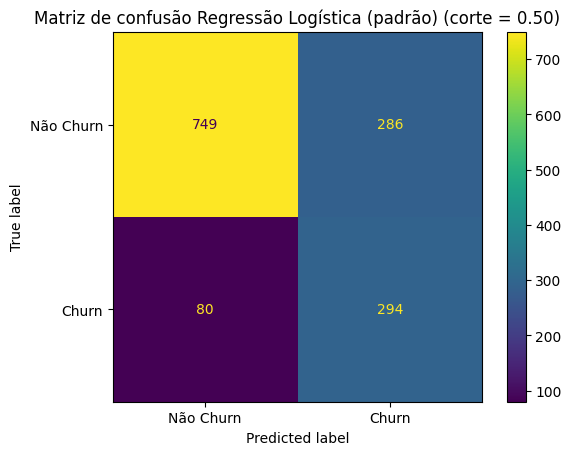

In [27]:
lr = modelo_lr().fit(x_train, y_train)
probas['Regressão Logística (padrão)'] = avaliar(lr, 'Regressão Logística (padrão)')

### Interpretação dos coeficientes

Numéricas estão padronizadas (efeito de +1 desvio padrão). Dummies são lidas contra a categoria de referência removida (por exemplo, `Contract_One year` é contra `Month-to-month`).

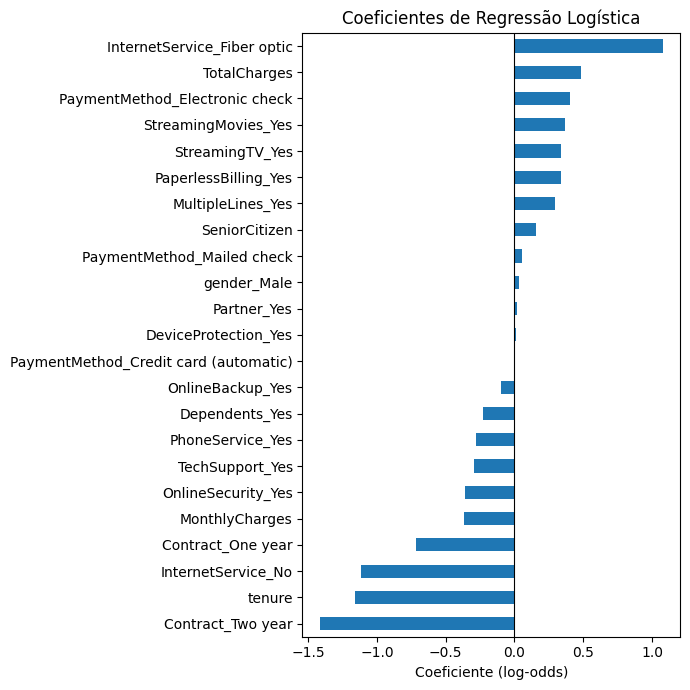

In [28]:
nomes = lr['prep'].get_feature_names_out()
coefs = pd.Series(lr['clf'].coef_[0], index=nomes).sort_values()

plt.figure(figsize=(7, 7))
coefs.plot(kind='barh')
plt.title('Coeficientes de Regressão Logística')
plt.xlabel('Coeficiente (log-odds)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## 5.2 Random Forest

              precision    recall  f1-score   support

   Não Churn       0.83      0.90      0.86      1035
       Churn       0.63      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409

ROC-AUC: 0.826 | PR-AUC: 0.618


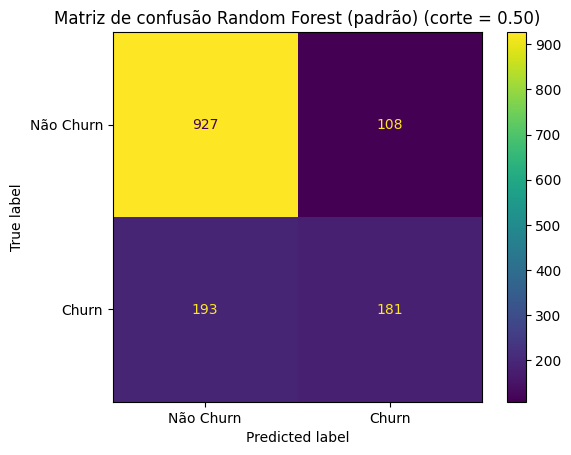

In [29]:
rf = modelo_rf().fit(x_train, y_train)
probas['Random Forest (padrão)'] = avaliar(rf, 'Random Forest (padrão)')

## 5.3 XGBoost (parâmetros padrão)

              precision    recall  f1-score   support

   Não Churn       0.90      0.74      0.81      1035
       Churn       0.52      0.78      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

ROC-AUC: 0.841 | PR-AUC: 0.658


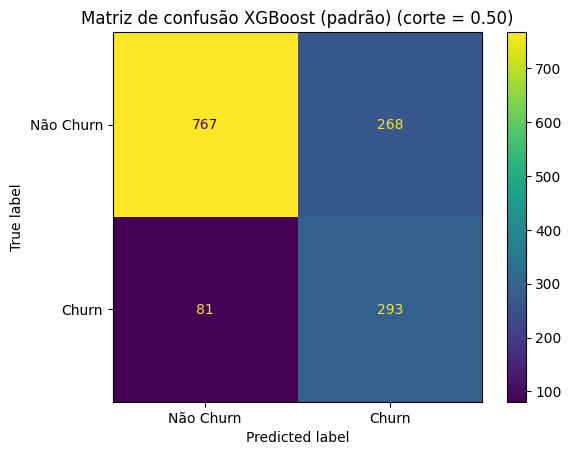

In [30]:
xgb_padrao = modelo_xgb(**PARAMS_PADRAO).fit(x_train, y_train)
probas['XGBoost (padrão)'] = avaliar(xgb_padrao, 'XGBoost (padrão)')

# 6. Otimização de Hiperparâmetros (Optuna) dos três algoritmos

Os três algoritmos recebem **o mesmo protocolo**: mesma CV estratificada de 5 folds no treino, mesma métrica (PR-AUC), mesmo número de trials e mesma semente. Assim a comparação final não favorece nenhum deles.

## 6.1 XGBoost

Cuidados para não contaminar a avaliação:

* A busca usa **somente o conjunto de treino**, com validação cruzada estratificada (5 folds). O teste só é usado no final.
* O pré-processamento está dentro do `Pipeline`, então é reajustado a cada fold. Não há vazamento entre treino e validação.
* A métrica otimizada é o **PR-AUC (average precision)**, que não depende do ponto de corte e é mais informativa que o ROC-AUC em base desbalanceada. O corte é escolhido depois, em função do recall.
* O espaço de busca de `max_depth` foi ampliado para começar em 1. Na primeira versão o melhor valor foi 2, que era o limite inferior, sinal de que o espaço estava limitando a busca.

In [31]:
N_TRIALS = 50

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 1, 8),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
    }
    scores = cross_val_score(modelo_xgb(**params), x_train, y_train, cv=cv, scoring='average_precision', n_jobs=1)
    return scores.mean()

estudo = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
estudo.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

print('Melhor PR-AUC (CV):', round(estudo.best_value, 4))
print('Melhores hiperparâmetros:')
for k, v in estudo.best_params.items():
    print(f'  {k}: {v}')

Melhor PR-AUC (CV): 0.6712
Melhores hiperparâmetros:
  n_estimators: 380
  learning_rate: 0.042391376805302236
  max_depth: 2
  min_child_weight: 10
  subsample: 0.6379679919943347
  colsample_bytree: 0.6914050302113515
  gamma: 3.7700194150442408
  reg_alpha: 6.452509986240249
  reg_lambda: 1.6347113042007797


In [32]:
# Algum hiperparâmetro encostou no limite do espaço de busca?
def posicao(v, lo, hi, log):
    return (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if log else (v - lo) / (hi - lo)

def checar_limites(estudo, limites):
    linhas = []
    for p, (lo, hi, log) in limites.items():
        v = estudo.best_params[p]
        pos = posicao(v, lo, hi, log)
        linhas.append({'hiperparâmetro': p, 'melhor': round(v, 4), 'faixa': f'{lo} a {hi}',
                       'posição na faixa (0 a 1)': round(pos, 2), 'perto do limite': 'SIM' if pos < 0.05 or pos > 0.95 else ''})
    return pd.DataFrame(linhas)

LIMITES_XGB = {'n_estimators': (100, 600, False), 'learning_rate': (0.01, 0.2, True), 'max_depth': (1, 8, False),
               'min_child_weight': (1, 10, False), 'subsample': (0.6, 1.0, False), 'colsample_bytree': (0.5, 1.0, False),
               'gamma': (0.0, 5.0, False), 'reg_alpha': (1e-3, 10.0, True), 'reg_lambda': (1e-3, 10.0, True)}
checar_limites(estudo, LIMITES_XGB)

,hiperparâmetro,melhor,faixa,posição na faixa (0 a 1),perto do limite
0,n_estimators,380.0000,100 a 600,0.56,
1,learning_rate,0.0424,0.01 a 0.2,0.48,
2,max_depth,2.0000,1 a 8,0.14,
3,min_child_weight,10.0000,1 a 10,1.00,SIM
4,subsample,0.6380,0.6 a 1.0,0.09,
5,colsample_bytree,0.6914,0.5 a 1.0,0.38,
6,gamma,3.7700,0.0 a 5.0,0.75,
7,reg_alpha,6.4525,0.001 a 10.0,0.95,SIM
8,reg_lambda,1.6347,0.001 a 10.0,0.80,


PR-AUC CV (split novo) XGBoost padrão  : 0.6626
PR-AUC CV (split novo) XGBoost Optuna  : 0.6704


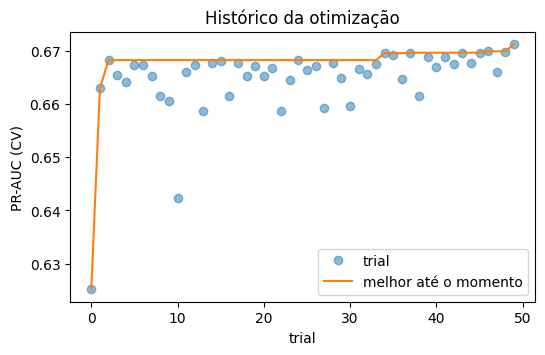

In [33]:
# Comparação de PR-AUC: XGBoost padrão contra o otimizado.
# Usa uma divisão de CV diferente da usada pelo Optuna, para o valor do otimizado não ficar inflado pela seleção.
cv_novo = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
pr_base = cross_val_score(modelo_xgb(**PARAMS_PADRAO), x_train, y_train, cv=cv_novo, scoring='average_precision').mean()
pr_opt = cross_val_score(modelo_xgb(**estudo.best_params), x_train, y_train, cv=cv_novo, scoring='average_precision').mean()
print('PR-AUC CV (split novo) XGBoost padrão  :', round(pr_base, 4))
print('PR-AUC CV (split novo) XGBoost Optuna  :', round(pr_opt, 4))

valores = [t.value for t in estudo.trials]
plt.figure(figsize=(6, 3.5))
plt.plot(valores, 'o', alpha=0.5, label='trial')
plt.plot(np.maximum.accumulate(valores), label='melhor até o momento')
plt.xlabel('trial'); plt.ylabel('PR-AUC (CV)'); plt.title('Histórico da otimização'); plt.legend()
plt.show()

              precision    recall  f1-score   support

   Não Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC: 0.848 | PR-AUC: 0.661


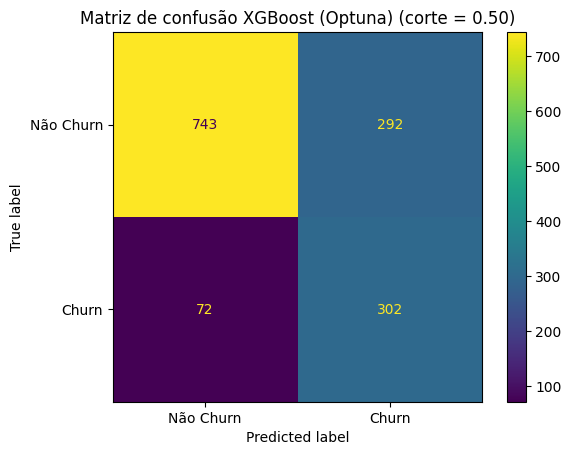

In [34]:
xgb_opt = modelo_xgb(**estudo.best_params).fit(x_train, y_train)
probas['XGBoost (Optuna)'] = avaliar(xgb_opt, 'XGBoost (Optuna)')

## 6.2 Regressão Logística (Optuna)

Espaço: força da regularização `C` (L2) e `class_weight` (sem peso ou balanceado). A penalidade L2 é mantida para a busca funcionar igual em qualquer versão do scikit-learn.

In [35]:
def modelo_lr_otm(**params):
    return Pipeline([('prep', novo_preprocessador()),
                     ('clf', LogisticRegression(max_iter=2000, random_state=SEED, **params))])

def objective_lr(trial):
    params = {
        'C': trial.suggest_float('C', 1e-3, 100.0, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
    }
    return cross_val_score(modelo_lr_otm(**params), x_train, y_train, cv=cv, scoring='average_precision', n_jobs=1).mean()

estudo_lr = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
estudo_lr.optimize(objective_lr, n_trials=50, show_progress_bar=False)

print('Melhor PR-AUC (CV):', round(estudo_lr.best_value, 4))
print('Melhores hiperparâmetros:', estudo_lr.best_params)
checar_limites(estudo_lr, {'C': (1e-3, 100.0, True)})

Melhor PR-AUC (CV): 0.6618
Melhores hiperparâmetros: {'C': 2.116782915589657, 'class_weight': None}


,hiperparâmetro,melhor,faixa,posição na faixa (0 a 1),perto do limite
0,C,2.1168,0.001 a 100.0,0.67,


              precision    recall  f1-score   support

   Não Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.842 | PR-AUC: 0.634


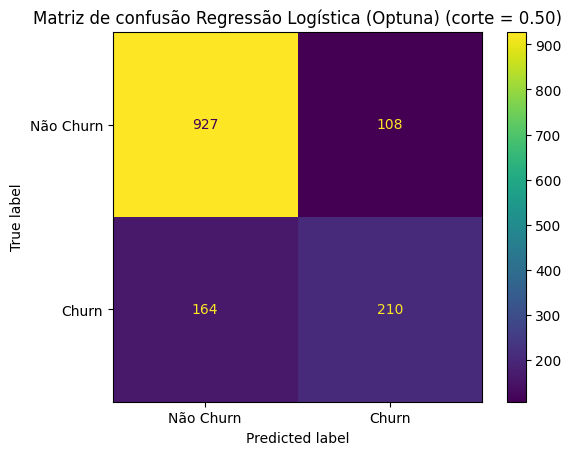

In [36]:
lr_opt = modelo_lr_otm(**estudo_lr.best_params).fit(x_train, y_train)
probas['Regressão Logística (Optuna)'] = avaliar(lr_opt, 'Regressão Logística (Optuna)')

## 6.3 Random Forest (Optuna)

Espaço: número de árvores, profundidade, tamanho mínimo de folha, fração de variáveis por divisão e `class_weight`.

In [37]:
def modelo_rf_otm(**params):
    return Pipeline([('prep', novo_preprocessador()),
                     ('clf', RandomForestClassifier(random_state=SEED, n_jobs=-1, **params))])

def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 30),
        'max_features': trial.suggest_float('max_features', 0.1, 1.0),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
    }
    return cross_val_score(modelo_rf_otm(**params), x_train, y_train, cv=cv, scoring='average_precision', n_jobs=1).mean()

estudo_rf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
estudo_rf.optimize(objective_rf, n_trials=50, show_progress_bar=False)

print('Melhor PR-AUC (CV):', round(estudo_rf.best_value, 4))
print('Melhores hiperparâmetros:', estudo_rf.best_params)
checar_limites(estudo_rf, {'n_estimators': (100, 500, False), 'max_depth': (3, 20, False),
                          'min_samples_leaf': (1, 30, False), 'max_features': (0.1, 1.0, False)})

Melhor PR-AUC (CV): 0.667
Melhores hiperparâmetros: {'n_estimators': 425, 'max_depth': 8, 'min_samples_leaf': 11, 'max_features': 0.45484754051806875, 'class_weight': 'balanced_subsample'}


,hiperparâmetro,melhor,faixa,posição na faixa (0 a 1),perto do limite
0,n_estimators,425.0000,100 a 500,0.81,
1,max_depth,8.0000,3 a 20,0.29,
2,min_samples_leaf,11.0000,1 a 30,0.34,
3,max_features,0.4548,0.1 a 1.0,0.39,


              precision    recall  f1-score   support

   Não Churn       0.91      0.76      0.83      1035
       Churn       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409

ROC-AUC: 0.846 | PR-AUC: 0.655


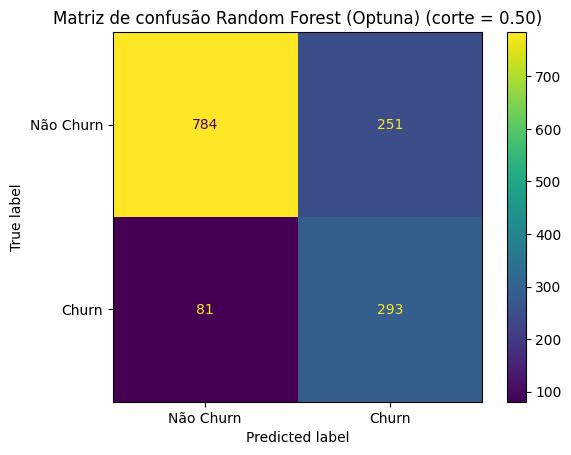

In [38]:
rf_opt = modelo_rf_otm(**estudo_rf.best_params).fit(x_train, y_train)
probas['Random Forest (Optuna)'] = avaliar(rf_opt, 'Random Forest (Optuna)')

In [39]:
# PR-AUC em CV com split novo (não usado pelo Optuna): padrão contra otimizado, para os três algoritmos
def pr_cv(modelo):
    return cross_val_score(modelo, x_train, y_train, cv=cv_novo, scoring='average_precision').mean()

comparativo_tuning = pd.DataFrame({
    'Regressão Logística': [pr_cv(modelo_lr()), pr_cv(modelo_lr_otm(**estudo_lr.best_params))],
    'Random Forest':       [pr_cv(modelo_rf()), pr_cv(modelo_rf_otm(**estudo_rf.best_params))],
    'XGBoost':             [pr_base, pr_opt],
}, index=['padrão', 'Optuna']).round(4)
comparativo_tuning

,Regressão Logística,Random Forest,XGBoost
padrão,0.6601,0.6298,0.6626
Optuna,0.6615,0.6650,0.6704


# 7. Ponto de Corte e Comparação Final

Como o falso negativo é o erro mais custoso, o corte de 0,5 não é necessariamente o ideal. **A mesma regra é aplicada aos seis modelos** (versão padrão e versão otimizada de cada algoritmo), para a comparação ser justa:

1. O corte é escolhido só com o treino, usando probabilidades out-of-fold (validação cruzada).
2. Regra: o **maior corte** que ainda mantém recall mínimo de 0,80 para Churn (na prática, a maior precisão possível sob essa restrição).
3. Esse corte é aplicado ao teste.

O recall de 0,80 é uma premissa de negócio e deve ser ajustado conforme a capacidade da área de retenção.

In [40]:
RECALL_ALVO = 0.80

def escolher_corte(modelo, X, y, cv, recall_alvo=RECALL_ALVO):
    proba_oof = cross_val_predict(modelo, X, y, cv=cv, method='predict_proba')[:, 1]
    prec, rec, thr = precision_recall_curve(y, proba_oof)
    validos = np.where(rec[:-1] >= recall_alvo)[0]
    i = validos[-1]
    return thr[i], rec[i], prec[i]

modelos_finais = {
    'Regressão Logística (padrão)': (modelo_lr, {}),
    'Regressão Logística (Optuna)': (modelo_lr_otm, estudo_lr.best_params),
    'Random Forest (padrão)': (modelo_rf, {}),
    'Random Forest (Optuna)': (modelo_rf_otm, estudo_rf.best_params),
    'XGBoost (padrão)': (modelo_xgb, PARAMS_PADRAO),
    'XGBoost (Optuna)': (modelo_xgb, estudo.best_params),
}

cortes = {}
for nome, (fabrica, params) in modelos_finais.items():
    corte, r_oof, p_oof = escolher_corte(fabrica(**params), x_train, y_train, cv)
    cortes[nome] = corte
    print(f'{nome:30s} corte = {corte:.3f}   (OOF no treino: recall = {r_oof:.3f}, precisão = {p_oof:.3f})')

Regressão Logística (padrão)   corte = 0.505   (OOF no treino: recall = 0.800, precisão = 0.521)


Regressão Logística (Optuna)   corte = 0.267   (OOF no treino: recall = 0.800, precisão = 0.522)


Random Forest (padrão)         corte = 0.225   (OOF no treino: recall = 0.806, precisão = 0.482)


Random Forest (Optuna)         corte = 0.454   (OOF no treino: recall = 0.800, precisão = 0.522)


XGBoost (padrão)               corte = 0.469   (OOF no treino: recall = 0.800, precisão = 0.519)


XGBoost (Optuna)               corte = 0.512   (OOF no treino: recall = 0.800, precisão = 0.529)


In [41]:
def resumo(y_true, proba, corte):
    pred = (proba >= corte).astype(int)
    r = classification_report(y_true, pred, output_dict=True, zero_division=0)
    return {'Corte': corte, 'Recall Churn': r['1']['recall'], 'Precisão Churn': r['1']['precision'],
            'F1 Churn': r['1']['f1-score'], 'Acurácia': r['accuracy'],
            'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba)}

print('Teste, mesma regra de corte para todos:')
comparacao_final = pd.DataFrame({n: resumo(y_test, probas[n], cortes[n]) for n in modelos_finais}).round(3)
display(comparacao_final)

print('Referência, corte padrão 0,5 para todos:')
display(pd.DataFrame({n: resumo(y_test, probas[n], 0.5) for n in modelos_finais}).round(3))

Teste, mesma regra de corte para todos:


,Regressão Logística (padrão),Regressão Logística (Optuna),Random Forest (padrão),Random Forest (Optuna),XGBoost (padrão),XGBoost (Optuna)
Corte,0.505,0.267,0.225,0.454,0.469,0.512
Recall Churn,0.778,0.783,0.810,0.816,0.797,0.799
Precisão Churn,0.508,0.513,0.489,0.520,0.505,0.513
F1 Churn,0.615,0.620,0.610,0.635,0.618,0.625
Acurácia,0.741,0.745,0.725,0.751,0.739,0.745
ROC-AUC,0.842,0.842,0.826,0.846,0.841,0.848
PR-AUC,0.634,0.634,0.618,0.655,0.658,0.661


Referência, corte padrão 0,5 para todos:


,Regressão Logística (padrão),Regressão Logística (Optuna),Random Forest (padrão),Random Forest (Optuna),XGBoost (padrão),XGBoost (Optuna)
Corte,0.500,0.500,0.500,0.500,0.500,0.500
Recall Churn,0.786,0.561,0.484,0.783,0.783,0.807
Precisão Churn,0.507,0.660,0.626,0.539,0.522,0.508
F1 Churn,0.616,0.607,0.546,0.638,0.627,0.624
Acurácia,0.740,0.807,0.786,0.764,0.752,0.742
ROC-AUC,0.842,0.842,0.826,0.846,0.841,0.848
PR-AUC,0.634,0.634,0.618,0.655,0.658,0.661


### Quanto dessas diferenças é ruído?

O teste tem 1409 clientes (cerca de 374 churners). Intervalos de 95% por bootstrap para recall e precisão, e para a **diferença pareada** entre o XGBoost otimizado e as versões otimizadas dos outros dois (mesmas amostras em cada reamostragem).

In [42]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
idx_boot = rng.integers(0, len(yt), size=(2000, len(yt)))

def boot_metricas(proba, corte):
    pred = (proba >= corte).astype(int)
    yb, pb = yt[idx_boot], pred[idx_boot]
    tp = ((yb == 1) & (pb == 1)).sum(axis=1)
    fn = ((yb == 1) & (pb == 0)).sum(axis=1)
    fp = ((yb == 0) & (pb == 1)).sum(axis=1)
    return tp / (tp + fn), tp / np.maximum(tp + fp, 1)

boot = {n: boot_metricas(probas[n], cortes[n]) for n in modelos_finais}

def ic(v): return f'{v.mean():.3f}  [{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]'

print('Média e IC 95% (bootstrap no teste):')
display(pd.DataFrame({n: {'Recall': ic(boot[n][0]), 'Precisão': ic(boot[n][1])} for n in modelos_finais}))

ref = 'XGBoost (Optuna)'
dif = {}
for outro in ['Regressão Logística (Optuna)', 'Random Forest (Optuna)']:
    dif[f'{ref} menos {outro}'] = {'Δ Recall': ic(boot[ref][0] - boot[outro][0]), 'Δ Precisão': ic(boot[ref][1] - boot[outro][1])}
print('Diferença pareada (IC contendo 0 = diferença indistinguível de ruído):')
display(pd.DataFrame(dif).T)

Média e IC 95% (bootstrap no teste):


,Regressão Logística (padrão),Regressão Logística (Optuna),Random Forest (padrão),Random Forest (Optuna),XGBoost (padrão),XGBoost (Optuna)
Recall,0.778 [0.734; 0.819],0.783 [0.738; 0.822],0.810 [0.770; 0.851],0.815 [0.774; 0.854],0.797 [0.755; 0.838],0.799 [0.757; 0.839]
Precisão,0.507 [0.467; 0.549],0.513 [0.472; 0.552],0.488 [0.447; 0.528],0.519 [0.479; 0.560],0.504 [0.463; 0.545],0.512 [0.471; 0.554]


Diferença pareada (IC contendo 0 = diferença indistinguível de ruído):


,Δ Recall,Δ Precisão
XGBoost (Optuna) menos Regressão Logística (Optuna),0.016 [-0.008; 0.041],-0.001 [-0.017; 0.016]
XGBoost (Optuna) menos Random Forest (Optuna),-0.016 [-0.038; 0.003],-0.007 [-0.018; 0.005]


### Validação cruzada aninhada (média ± desvio)

Um único split de teste não mostra a variabilidade. Aqui, os três modelos otimizados são avaliados em validação cruzada repetida (5 folds x 2 repetições) **sobre o treino**. Em cada fold externo, o corte é escolhido apenas com os dados de treino daquele fold (CV interna), exatamente como na regra acima. O teste continua intocado.

Observação: os hiperparâmetros dos três modelos foram escolhidos no mesmo treino, então os números tendem a ser levemente otimistas para os três por igual.

In [43]:
cv_externa = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

def cv_aninhada(fabrica, X, y):
    linhas = []
    for tr, va in cv_externa.split(X, y):
        Xtr, Xva, ytr, yva = X.iloc[tr], X.iloc[va], y.iloc[tr], y.iloc[va]
        corte, _, _ = escolher_corte(fabrica(), Xtr, ytr, cv)
        proba = fabrica().fit(Xtr, ytr).predict_proba(Xva)[:, 1]
        pred = (proba >= corte).astype(int)
        linhas.append({'Recall': recall_score(yva, pred), 'Precisão': precision_score(yva, pred),
                       'ROC-AUC': roc_auc_score(yva, proba), 'PR-AUC': average_precision_score(yva, proba)})
    return pd.DataFrame(linhas)

resultados_cv = {}
for nome in ['Regressão Logística (Optuna)', 'Random Forest (Optuna)', 'XGBoost (Optuna)']:
    fabrica, params = modelos_finais[nome]
    resultados_cv[nome] = cv_aninhada(lambda: fabrica(**params), x_train, y_train)

tabela_cv = pd.DataFrame({n: r.agg(lambda c: f'{c.mean():.3f} ± {c.std():.3f}') for n, r in resultados_cv.items()})
tabela_cv

,Regressão Logística (Optuna),Random Forest (Optuna),XGBoost (Optuna)
Recall,0.799 ± 0.039,0.802 ± 0.026,0.811 ± 0.029
Precisão,0.523 ± 0.017,0.520 ± 0.017,0.526 ± 0.016
ROC-AUC,0.846 ± 0.012,0.847 ± 0.012,0.851 ± 0.012
PR-AUC,0.661 ± 0.018,0.666 ± 0.019,0.672 ± 0.018


# 8. Interpretação do XGBoost (SHAP)

A Regressão Logística era o único modelo interpretado. Aqui o XGBoost otimizado é explicado com SHAP no conjunto de teste: o gráfico de barras mostra a importância média e o de pontos mostra a direção do efeito (vermelho = valor alto da variável).

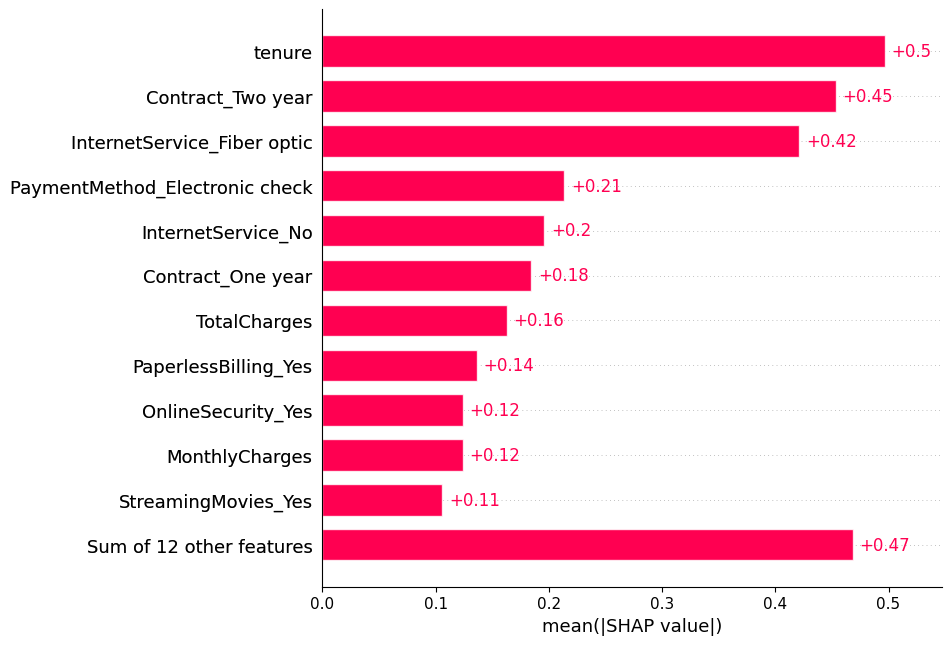

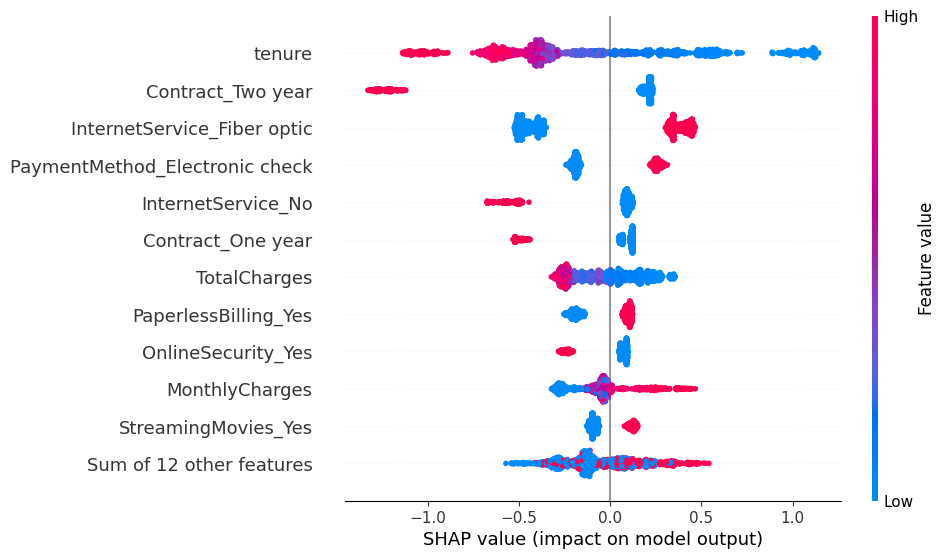

In [44]:
prep_final = xgb_opt['prep']
x_test_t = prep_final.transform(x_test)
explicador = shap.TreeExplainer(xgb_opt['clf'])
valores_shap = explicador(x_test_t)

shap.plots.bar(valores_shap, max_display=12)
shap.plots.beeswarm(valores_shap, max_display=12)

In [45]:
imp_shap = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=x_test_t.columns).sort_values(ascending=False)
coefs_otm = pd.Series(lr_opt['clf'].coef_[0], index=lr_opt['prep'].get_feature_names_out())
imp_lr = coefs_otm.abs().sort_values(ascending=False)

pd.DataFrame({'Top 8 SHAP (XGBoost)': imp_shap.head(8).index, 'Top 8 |coef| (Reg. Logística)': imp_lr.head(8).index})

,Top 8 SHAP (XGBoost),Top 8 |coef| (Reg. Logística)
0,tenure,InternetService_No
1,Contract_Two year,InternetService_Fiber optic
2,InternetService_Fiber optic,Contract_Two year
3,PaymentMethod_Electronic check,tenure
4,InternetService_No,MonthlyCharges
5,Contract_One year,Contract_One year
6,TotalCharges,TotalCharges
7,PaperlessBilling_Yes,StreamingTV_Yes


## 9. Considerações Finais

O falso negativo (não identificar quem vai cancelar) é o erro mais custoso, então o recall de Churn é a métrica prioritária. Os três algoritmos receberam o **mesmo protocolo de otimização** (Optuna, 50 trials, mesma CV de 5 folds, PR-AUC) e **a mesma regra de corte**: o maior corte que mantém recall ≥ 0,80 em validação cruzada no treino.

**Resultado (teste, 1409 clientes, modelos otimizados)**

| Modelo | Recall | Precisão | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| Regressão Logística | 0,783 | 0,513 | 0,620 | 0,842 | 0,634 |
| Random Forest | 0,816 | 0,520 | 0,635 | 0,846 | 0,655 |
| XGBoost | 0,799 | 0,513 | 0,625 | 0,848 | 0,661 |

**Validação cruzada aninhada (treino, média ± desvio)**

| Modelo | Recall | Precisão | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| Regressão Logística | 0,799 ± 0,039 | 0,523 ± 0,017 | 0,846 ± 0,012 | 0,661 ± 0,018 |
| Random Forest | 0,802 ± 0,026 | 0,520 ± 0,017 | 0,847 ± 0,012 | 0,666 ± 0,019 |
| XGBoost | 0,811 ± 0,029 | 0,526 ± 0,016 | 0,851 ± 0,012 | 0,672 ± 0,018 |

**Efeito do tuning** (PR-AUC em CV com split novo, padrão para otimizado): Regressão Logística 0,660 para 0,662, Random Forest 0,630 para 0,665 e XGBoost 0,663 para 0,670. O Random Forest foi o que mais ganhou, e com a comparação justa ele alcançou os outros dois.

**Leitura**

* **Os três modelos estão tecnicamente empatados.** Na diferença pareada do XGBoost contra os outros (bootstrap no teste), todos os intervalos de 95% contêm zero: contra a Regressão Logística, recall +0,016 [−0,008; 0,041] e precisão −0,001 [−0,017; 0,016]; contra o Random Forest, recall −0,016 [−0,038; 0,003] e precisão −0,007 [−0,018; 0,005].
* O XGBoost lidera ROC-AUC e PR-AUC na CV, mas a margem (cerca de 0,006 a 0,011 em PR-AUC) é menor que o desvio entre folds (0,018). É uma vantagem consistente na direção, porém não conclusiva.
* A conclusão da versão anterior (XGBoost melhor que o Random Forest) **não se sustentou** quando o Random Forest recebeu o mesmo tuning. Essa vantagem vinha de comparar um modelo otimizado com um padrão.
* Como o desempenho é equivalente, a escolha deve se apoiar em outros critérios: a Regressão Logística é a mais simples, rápida e interpretável; o XGBoost tem leve vantagem nas métricas independentes de corte.
* Desbalanceamento: pesos de classe e SMOTENC dão ROC-AUC e PR-AUC equivalentes (SMOTENC levemente menor), então não houve ganho em gerar dados sintéticos.
* Espaço de busca do XGBoost: `max_depth` ficou em 2 (dentro da faixa), mas `min_child_weight` (10) e `reg_alpha` (6,5) ficaram perto do teto. O modelo ótimo é simples e bastante regularizado, e ampliar esses limites é um próximo passo.

**Interpretação**

* Regressão Logística e SHAP (XGBoost) concordam nos principais fatores: `tenure`, contrato de 2 anos, internet por fibra ótica, ausência de internet, Electronic check e contrato de 1 ano aparecem entre os mais importantes nos dois.
* Pelos coeficientes da Regressão Logística: maior tempo de permanência e contratos mais longos reduzem o risco de churn; fibra ótica, pagamento por Electronic check, fatura digital (PaperlessBilling) e streaming aumentam. Ter OnlineSecurity e TechSupport reduz o risco.
* Cuidado com `MonthlyCharges` e `TotalCharges`: têm VIF alto (seção 4.1) e sinais opostos (negativo para `MonthlyCharges`, positivo para `TotalCharges`), o que reflete colinearidade. Esses dois coeficientes não devem ser lidos isoladamente.

**Limitações**

* Os hiperparâmetros dos três modelos foram escolhidos no mesmo treino usado na CV aninhada, então os números dessa tabela tendem a ser levemente otimistas, por igual para os três.
* O teste tem 1409 clientes (cerca de 374 churners), por isso diferenças de 1 a 2 pontos percentuais estão dentro do ruído.
* O recall mínimo de 0,80 é uma premissa e deveria ser definido com a área de retenção.

**Próximos passos:** ampliar o espaço do Optuna para o XGBoost, comparar com CatBoost e incorporar o custo de falso positivo e falso negativo numa análise de retorno financeiro das campanhas de retenção.